# Solving a bar with the Riesz theorem: a truncated series in an orthonormal polynomial basis

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 4, Section "Dual Spaces and the Riesz Representation Theorem" and Example
"Coercivity of the Bar: the Poincaré Inequality in Action".

A bar of length $L = 1$, clamped at $x = 0$ and free at $x = 1$, has stiffness $k(x)$ and carries a distributed
load $f(x)$ and a tip force $F$. Its displacement $u \in \mathcal{V} = \{v \in H^1(0,1) : v(0) = 0\}$ solves
$$a(u, v) = \ell(v) \quad \forall v \in \mathcal{V}, \qquad
  a(u, v) = \int_0^1 k\, u' v'\, dx, \qquad \ell(v) = \int_0^1 f\, v\, dx + F\, v(1).$$

The Example in the book shows that, when $0 < k_{\min} \le k(x) \le k_{\max}$, the form $a$ is bounded
($M = k_{\max}$) and coercive ($\alpha = k_{\min}/(1 + L^2/2)$): the hypotheses of Lax–Milgram hold. Since $a$ is
also symmetric, it is an inner product on $\mathcal{V}$, the **energy inner product**, and the solution is the Riesz
representative of the load in that inner product. If $(e_i)$ is an orthonormal basis for $a$,
$$u = \sum_{i=1}^{\infty} \ell(e_i)\, e_i .$$
Truncating the series after $N$ terms gives an approximation $u_N$; this notebook builds the $e_i$ from the
monomials by Gram–Schmidt and watches how fast $u_N$ approaches $u$, first for a smooth stiffness, then for a
stiffness that jumps.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- PARAMETERS
N_max   = 12      # largest number of basis functions x, x^2, ..., x^N_max
N_plot  = [1, 2, 4, 8]   # truncations shown in the plots
F       = 0.0     # tip force at x = 1 (the distributed load is f = 1)
k_left  = 1.5     # jumping bar: stiffness on (0, x_jump) ...
k_right = 0.5     # ... and on (x_jump, 1)
x_jump  = 0.5
# ---------------------------------------------------------------------------

## 1. Ingredients: quadrature, monomials, Gram–Schmidt

Integrals are computed with Gauss–Legendre quadrature on $(0, x_{\rm jump})$ and $(x_{\rm jump}, 1)$ separately,
60 points each, so that piecewise-constant stiffnesses are integrated exactly. Each function is stored through
its values and derivatives at the quadrature points and its tip value $v(1)$: this is all that $a$ and $\ell$ need.

The starting functions $x, x^2, \dots, x^N$ all satisfy the boundary condition $v(0) = 0$. Gram–Schmidt in the
energy inner product,
$$\tilde e_n = x^n - \sum_{j<n} a(x^n, e_j)\, e_j, \qquad e_n = \tilde e_n / \sqrt{a(\tilde e_n, \tilde e_n)},$$
makes them orthonormal **for the given $k$**: change the stiffness and the basis changes. We orthogonalize twice
against the previous functions ("twice is enough"), because the monomials are nearly parallel and a single pass
loses orthogonality in double precision (see the notebook `ch04_angle_basis`).

In [2]:
def gauss(a, b, n=60):
    xg, wg = np.polynomial.legendre.leggauss(n)
    return (b - a) / 2 * xg + (a + b) / 2, (b - a) / 2 * wg

x1, w1 = gauss(0, x_jump); x2, w2 = gauss(x_jump, 1)
xq, wq = np.concatenate([x1, x2]), np.concatenate([w1, w2])

def monomials(N, x):
    """Values and derivatives of x^n, n = 1..N, at the points x; tip values at x = 1."""
    n = np.arange(1, N + 1)[:, None]
    return x**n, n * x**(n - 1), np.ones(N)

def gram_schmidt(val, der, tip, k):
    """Orthonormalize the functions (rows) in the inner product a(u,v) = int k u' v'."""
    a = lambda d1, d2: np.sum(wq * k * d1 * d2)
    E_val, E_der, E_tip = [], [], []
    for v, d, t in zip(val, der, tip):
        for _ in range(2):                                   # orthogonalize twice
            for ev, ed, et in zip(E_val, E_der, E_tip):
                c = a(d, ed)
                v, d, t = v - c * ev, d - c * ed, t - c * et
        nrm = np.sqrt(a(d, d))
        E_val.append(v / nrm); E_der.append(d / nrm); E_tip.append(t / nrm)
    return np.array(E_val), np.array(E_der), np.array(E_tip)

def load(val, tip):
    """ell(v) = int f v dx + F v(1), with f = 1."""
    return val @ wq + F * tip

def riesz_bar(k_fun, u_exact, du_exact, name):
    """Truncated Riesz series for the bar; returns the energy errors and the data for the plots."""
    k = k_fun(xq)
    E_val, E_der, E_tip = gram_schmidt(*monomials(N_max, xq), k)
    G = (E_der * wq * k) @ E_der.T
    print(f"{name}: largest deviation of a(e_i, e_j) from the identity = {np.abs(G - np.eye(N_max)).max():.1e}")
    coef = load(E_val, E_tip)                               # ell(e_i): the Fourier coordinates of u
    energy = np.sum(wq * u_exact(xq)) + F * u_exact(1.0)    # ||u||_a^2 = ell(u)  (Clapeyron)
    err = []
    for N in range(1, N_max + 1):
        du_N = coef[:N] @ E_der[:N]
        err.append(np.sqrt(np.sum(wq * k * (du_exact(xq) - du_N)**2) / energy))
    print(f"{name}: Parseval check, sum ell(e_i)^2 = {np.sum(coef**2):.10f},  ||u||_a^2 = {energy:.10f}")
    return np.array(err), coef

To plot $u_N$ and the axial force $N_N = k\, u_N'$ on a fine grid, we need the basis functions everywhere, not only
at the quadrature points. Gram–Schmidt is linear: each $e_i$ is a fixed combination of the monomials, and we
recover the combination coefficients by repeating the procedure on the identity matrix.

In [3]:
def combination_matrix(k_fun):
    """Matrix C such that e_i = sum_j C_ij x^(j+1)."""
    k = k_fun(xq)
    val, der, tip = monomials(N_max, xq)
    C = np.eye(N_max)
    a = lambda d1, d2: np.sum(wq * k * d1 * d2)
    rows, ders = [], []
    for n in range(N_max):
        c, d = C[n].copy(), der[n].copy()
        for _ in range(2):
            for cj, dj in zip(rows, ders):
                s = a(d, dj)
                c, d = c - s * cj, d - s * dj
        nrm = np.sqrt(a(d, d))
        rows.append(c / nrm); ders.append(d / nrm)
    return np.array(rows)

def plot_case(k_fun, u_exact, du_exact, coef, title):
    C = combination_matrix(k_fun)
    x = np.linspace(0, 1, 801)
    val, der, _ = monomials(N_max, x)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    for N in N_plot:
        cN = coef[:N] @ C[:N]                               # u_N in the monomial basis
        ax[0].plot(x, cN @ val, label=f"$N={N}$")
        ax[1].plot(x, k_fun(x) * (cN @ der), label=f"$N={N}$")
    ax[0].plot(x, u_exact(x), "k--", label="exact")
    ax[1].plot(x, k_fun(x) * du_exact(x), "k--", label="exact")
    ax[0].set_title(f"{title}: displacement $u_N$"); ax[1].set_title(f"{title}: axial force $k\\,u_N'$")
    for a in ax: a.set_xlabel("$x$"); a.legend(fontsize=8)
    plt.show()

## 2. A smooth bar: $k(x) = 3/2 - x$

The bar softens towards its free end: $k_{\min} = 1/2$ at $x = 1$, $k_{\max} = 3/2$ at $x = 0$, so Lax–Milgram
applies with $M = 3/2$ and $\alpha = (1/2)/(1 + 1/2) = 1/3$.
The axial force is fixed by equilibrium alone, $N(x) = \int_x^1 f\, ds + F = 1 - x + F$, hence
$$u'(x) = \frac{1 - x + F}{3/2 - x}, \qquad u(x) = x + \Big(\frac12 - F\Big)\ln\Big(1 - \frac{2x}{3}\Big) .$$
The solution is analytic on $[0, 1]$, and the polynomials should have no difficulty.

Lax-Milgram constants: M = 1.5,  alpha = 0.3333
smooth: largest deviation of a(e_i, e_j) from the identity = 8.9e-16
smooth: Parseval check, sum ell(e_i)^2 = 0.2746530722,  ||u||_a^2 = 0.2746530722


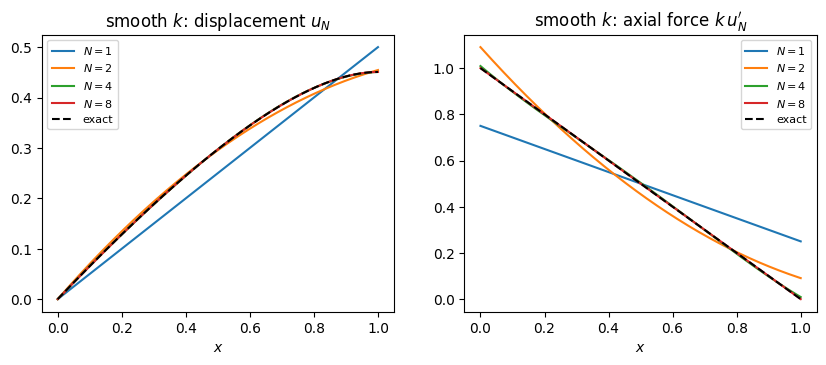

In [4]:
k_s  = lambda x: 1.5 - x
u_s  = lambda x: x + (0.5 - F) * np.log(1 - 2 * x / 3)
du_s = lambda x: (1 - x + F) / (1.5 - x)

print(f"Lax-Milgram constants: M = {1.5},  alpha = {0.5 / 1.5:.4f}")
err_s, coef_s = riesz_bar(k_s, u_s, du_s, "smooth")
plot_case(k_s, u_s, du_s, coef_s, "smooth $k$")

Already with $N = 4$ the curves are indistinguishable from the exact ones, both for the displacement and for
the axial force.

## 3. A bar whose stiffness jumps

Now $k = k_{\rm left}$ on $(0, x_{\rm jump})$ and $k = k_{\rm right}$ on $(x_{\rm jump}, 1)$, as in a bar made of two
materials. Lax–Milgram still applies, with $M = \max(k_{\rm left}, k_{\rm right})$ and
$\alpha = \min(k_{\rm left}, k_{\rm right})/(1 + 1/2)$: the theory does not care about the jump. The axial force is
the same as before, $N = 1 - x + F$, continuous, but the strain $u' = N/k$ jumps at $x_{\rm jump}$ and the
displacement has a kink there.

Lax-Milgram constants: M = 1.5,  alpha = 0.3333
jump: largest deviation of a(e_i, e_j) from the identity = 4.4e-16
jump: Parseval check, sum ell(e_i)^2 = 0.2730833729,  ||u||_a^2 = 0.2777777778


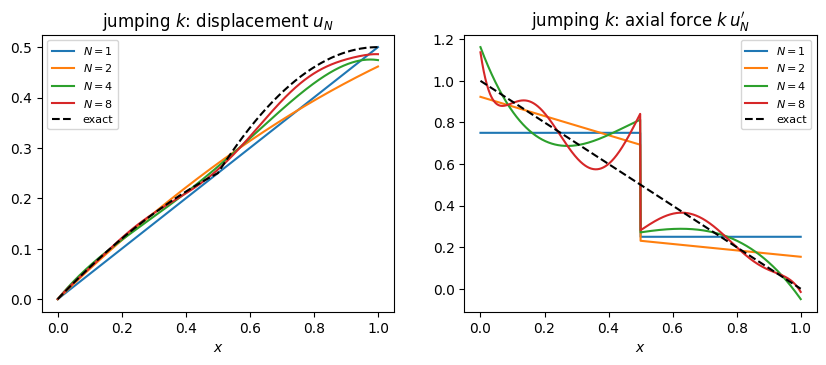

In [5]:
k_j  = lambda x: np.where(x < x_jump, k_left, k_right)
du_j = lambda x: (1 - x + F) / k_j(x)
def u_j(x):
    x = np.asarray(x, dtype=float)
    prim = lambda s: (1 + F) * s - s**2 / 2                 # primitive of N(s) = 1 - s + F
    return np.where(x < x_jump, prim(x) / k_left,
                    prim(x_jump) / k_left + (prim(x) - prim(x_jump)) / k_right)

print(f"Lax-Milgram constants: M = {max(k_left, k_right)},  alpha = {min(k_left, k_right) / 1.5:.4f}")
err_j, coef_j = riesz_bar(k_j, u_j, du_j, "jump")
plot_case(k_j, u_j, du_j, coef_j, "jumping $k$")

The displacement is still fairly good, but the axial force is not. Equilibrium says it is the straight line
$1 - x + F$, continuous across the interface; the approximate one, $k\,u_N'$, jumps there, because $u_N'$ is a
polynomial, continuous everywhere, while $k$ jumps. Each $u_N$ is the best approximation of $u$ in the energy norm
among the polynomials of degree $N$ vanishing at $x = 0$; no polynomial can have the kink of $u$.

## 4. How fast does the truncated series converge?

The relative error in the energy norm, $\|u - u_N\|_a / \|u\|_a$. By Pythagoras (the coordinates $\ell(e_i)$ beyond
$N$ are discarded), its square is $1 - \sum_{i \le N} \ell(e_i)^2 / \|u\|_a^2$: Parseval's identity, read backwards.

 N   smooth      jump
 1   3.00e-01   3.16e-01
 2   8.37e-02   2.77e-01
 3   2.28e-02   2.74e-01
 4   6.18e-03   2.11e-01
 5   1.67e-03   2.06e-01
 6   4.48e-04   1.78e-01
 7   1.20e-04   1.72e-01
 8   3.23e-05   1.57e-01
 9   8.68e-06   1.52e-01
10   2.33e-06   1.42e-01
11   6.25e-07   1.37e-01
12   1.68e-07   1.30e-01


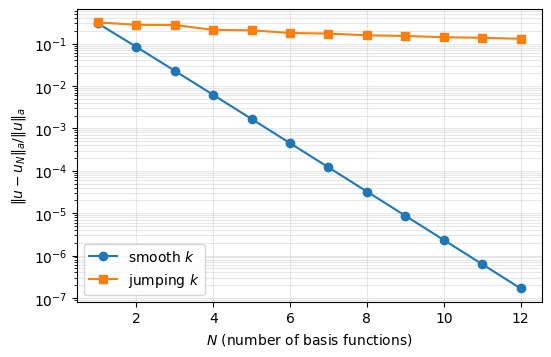

In [6]:
Ns = np.arange(1, N_max + 1)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.semilogy(Ns, err_s, "o-", label="smooth $k$")
ax.semilogy(Ns, err_j, "s-", label="jumping $k$")
ax.set_xlabel("$N$ (number of basis functions)"); ax.set_ylabel(r"$\|u-u_N\|_a/\|u\|_a$")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.show()
print(" N   smooth      jump")
for N, es, ej in zip(Ns, err_s, err_j):
    print(f"{N:2d}   {es:.2e}   {ej:.2e}")

For the smooth bar the error drops by a roughly constant factor at each new function: exponential convergence,
until round-off takes over, a little beyond the default `N_max = 12`. For the jumping bar the error decreases like a power of $N$, slowly:
doubling $N$ gains little. Same theorem, same basis-building recipe, very different outcomes. The cure is not more
polynomials but a different basis, one whose functions may have a kink at $x_{\rm jump}$ — for instance piecewise
polynomials, which is the idea of the finite element method.

## Things to try
1. Set `k_right = k_left`: the jump disappears and the polynomials recover the exact solution, a polynomial of
   degree 2, as soon as $N = 2$.
2. Make the jump stronger (`k_right = 0.05`, a damaged region): the coercivity constant $\alpha$ drops and the error
   of the jumping bar grows. Does the rate of convergence change?
3. Move the interface to `x_jump = 1/3`. Does it matter where the kink is?
4. Increase `N_max` to 20. The orthogonality check stays perfect, yet beyond $N \approx 14$ the smooth-bar error
   *grows* and the Parseval sum exceeds $\|u\|_a^2$: in double precision the new monomials are almost
   combinations of the previous ones, and what Gram–Schmidt extracts from them, and normalizes, is round-off.
   The cure is a better-conditioned starting set (Legendre polynomials, for instance), not more digits.
5. Add a tip force, `F = 1`. Only the coordinates $\ell(e_i)$ change: the basis depends on $k$, not on the load.